# Bölüm 13 – Makale Yeniden Üretimi: GADGET ile Bölgesel Etki Grafikleri

**Öğrenci:** Serap Şahin (20269348009)

**Makale:** Herbinger, J., Wright, M. N., Nagler, T., Bischl, B. ve Casalicchio, G. (2024). *Decomposing Global Feature
Effects Based on Feature Interactions.* Journal of Machine Learning Research, 25(381), 1–65.
https://jmlr.org/papers/v25/23-0699.html · Yazarların kodu (R): github.com/JuliaHerbinger/gadget

**İzlencedeki tür:** Seçenek 2 (Kıyaslama). Global PDP/ICE ile GADGET'in bölgesel etkilerinin; tek öznitelikli ve çok
öznitelikli bölmenin karşılaştırılması.

**Ana soru:** PDP, ICE eğrilerinin ortalamasıdır. Bir öznitelik başka özniteliklerle etkileşim içindeyse ICE eğrileri
farklı şekillerde gider ve ortalama bu farkı gizler. GADGET, ICE eğrilerini **bir karar ağacıyla** benzer şekilli
eğrilerin bir arada olduğu bölgelere ayırır. REPID (aynı ekibin 2022 bildirisi) bunu tek bir öznitelik için yapıyordu;
GADGET **birden çok özniteliğin** ICE eğrilerini aynı anda ele alır.

**Defterin akışı**

| Kısım | İçerik | Derste |
|---|---|---|
| 1 | Yöntemi sıfırdan yazmak: merkezleme, çok öznitelikli heterojenlik, ızgara kısıtlama, ağaç | 🔴 **Canlı** |
| 2 | Makalenin simülasyonu (Bölüm 4): y = 3x₁·işaret(x₃) + x₃ + ε | 🔴 **Canlı** + hazır |
| 3 | Makalenin gerçek veri örneği (Bölüm 1): saatlik bisiklet verisi, saat için ICE | Hazır |
| 4 | Kendi verim: Bölüm 13 uygulamamdaki model; tek öznitelik (REPID) ile çok öznitelikli GADGET, dört kurgu | Hazır |
| 5 | Sınırlamalar | Tartışma |

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#EBEBEB",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
BOLGE_RENK = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02"]

SEKIL = Path("sekiller")
SEKIL.mkdir(exist_ok=True)


def goster(fig, ad):
    """Grafiği sunumda kullanmak için sekiller/ klasörüne kaydeder ve gösterir."""
    fig.savefig(SEKIL / ad, dpi=150, bbox_inches="tight")
    plt.show()


# veri.csv = California Housing (Bölüm 13 uygulamamdaki dosya). veri_bisiklet.csv = makalenin kullandığı saatlik
# bisiklet verisi (ISLR2/ISLP `Bikeshare`, 8.645 saat). Dosya bulunamazsa aynı sabit sürüm indirilir.
VERI = {
    "california": ("veri.csv", "https://raw.githubusercontent.com/ageron/handson-ml2/"
                               "7b7e23e7267356f8355580877eff98c43cda1bd0/datasets/housing/housing.csv"),
    "bisiklet": ("veri_bisiklet.csv", None),
}


def veri_oku(ad):
    dosya, url = VERI[ad]
    return pd.read_csv(dosya if Path(dosya).exists() or url is None else url)


def ice_hesapla(tahmin_fn, X, ozellik, izgara):
    """n x K ICE matrisi (satır = gözlem, sütun = ızgara noktası). Bölüm 13 uygulamamdaki fonksiyon."""
    n, K = len(X), len(izgara)
    X_cogul = pd.concat([X] * K, ignore_index=True)
    X_cogul[ozellik] = np.repeat(np.asarray(izgara), n)
    return np.asarray(tahmin_fn(X_cogul)).reshape(K, n).T

## 1. 🔴 Canlı kodlama: GADGET'i sıfırdan yazmak (ICE/PD sürümü)

Yazarların koduna (`R/tree_splitting.R`, `R/helper_tree_splitting.R`, `SS_L2_pd`) göre:

**1. Merkezleme.** İlgilenilen her öznitelik $j \in S$ için ICE eğrileri kendi ortalamalarına göre merkezlenir:
$\tilde f_j^{(i)}(z_k) = \hat f_j^{(i)}(z_k) - \frac{1}{K}\sum_{k'} \hat f_j^{(i)}(z_{k'})$. Seviye silinir, şekil kalır.

**2. Çok öznitelikli heterojenlik.** Bir bölgedeki heterojenlik, $S$'deki **bütün** özniteliklerin eğrilerinin kendi
bölgesel PDP'lerine kare uzaklıklarının toplamıdır:

$$\mathcal{R}(\mathcal{N}) = \sum_{j \in S} \sum_{i \in \mathcal{N}} \sum_{k} \big(\tilde f_j^{(i)}(z_k) - \bar{\tilde f}_{j,\mathcal{N}}(z_k)\big)^2$$

**3. Izgara kısıtlama.** Bölünen öznitelik $S$'nin içindeyse (örneğin $x_3$'e göre bölüp $x_3$'ün etkisine de bakıyorsak),
o özniteliğin ızgarası her çocukta kendi tarafıyla sınırlanır ($z \le t$ solda, $z > t$ sağda) ve eğriler kalan
noktalar üzerinden yeniden merkezlenir. Böylece her bölge yalnızca kendi değer aralığındaki etkiyi gösterir.

**4. Durma kuralı (REPID ile aynı).** Kazanç = (düğüm − sol − sağ) / kök. İlk bölünme kazanç ≥ `esik` ise; sonrakiler bir
önceki kazancın `esik` katından büyükse yapılır.

**REPID ile ilişkisi:** $S$ tek öznitelik ve bölünme o öznitelikte değilse GADGET'in PD sürümü REPID'e eşittir.

In [2]:
def merkezle(Y):
    """Her eğriyi kendi ortalamasına göre merkezler (NaN sütunlar, yani ızgara dışı noktalar, yok sayılır)."""
    return Y - np.nanmean(Y, axis=1, keepdims=True)


def heterojenlik(Y):
    """Tek öznitelik: eğrilerin bölgesel PDP'den kare uzaklıklarının toplamı."""
    if len(Y) == 0:
        return 0.0
    return float(np.nansum((Y - np.nanmean(Y, axis=0)) ** 2))


def cocuk_egrileri(ICE, izgara, idx, bolunen=None, t=None, taraf=None):
    """Bir düğümün eğrileri: her j ∈ S için o düğümdeki gözlemler; bölünen öznitelik S'deyse ızgarası kısıtlanır ve
    eğriler kalan noktalar üzerinden yeniden merkezlenir. izgara[j] düğümün o anki ızgarasıdır (boolean maske)."""
    sonuc, yeni_izgara = {}, {}
    for j, Y in ICE.items():
        maske = izgara[j].copy()
        if j == bolunen:
            z = ICE_IZGARA[j]
            maske &= (z <= t) if taraf == "sol" else (z > t)
        Yj = Y[idx].copy()
        Yj[:, ~maske] = np.nan
        sonuc[j], yeni_izgara[j] = merkezle(Yj), maske
    return sonuc, yeni_izgara


def toplam_heterojenlik(Ys):
    return sum(heterojenlik(Y) for Y in Ys.values())


def en_iyi_bolunme(ICE, izgara, idx, X, min_dugum=10, n_kantil=100):
    """Her bölme özniteliği ve eşik için iki çocuğun toplam heterojenliğini hesaplar, en küçüğünü seçer.
    Eşik adayları: yazarlar gibi en fazla 100 kantil noktası (n_kantil=None ise bütün değer geçişleri)."""
    en_iyi = (np.inf, None, None)
    for oz in X.columns:
        x = X[oz].to_numpy(dtype=float)[idx]
        d = np.unique(x)
        adaylar = (d[:-1] + d[1:]) / 2
        if n_kantil is not None and len(adaylar) > n_kantil:
            adaylar = np.unique(np.quantile(adaylar, np.linspace(0, 1, n_kantil)))
        for t in adaylar:
            sol = x <= t
            if sol.sum() < min_dugum or (~sol).sum() < min_dugum:
                continue
            Ys, _ = cocuk_egrileri(ICE, izgara, idx[sol], oz, t, "sol")
            Ya, _ = cocuk_egrileri(ICE, izgara, idx[~sol], oz, t, "sag")
            toplam = toplam_heterojenlik(Ys) + toplam_heterojenlik(Ya)
            if toplam < en_iyi[0]:
                en_iyi = (toplam, oz, t)
    return en_iyi


def gadget(ICE, X, derinlik=2, esik=0.1, min_dugum=10, n_kantil=100):
    """GADGET ağacı (PD sürümü). ICE: {öznitelik: merkezlenmemiş ICE matrisi}; X: bölme öznitelikleri.
    Döndürür: yapraklar (gözlem indeksleri, ızgara maskeleri, kural), bölünme tablosu, kök heterojenliği (öznitelik başına)."""
    tum = np.arange(len(X))
    kok_izgara = {j: np.ones(Y.shape[1], dtype=bool) for j, Y in ICE.items()}
    kok_Y, _ = cocuk_egrileri(ICE, kok_izgara, tum)
    kok = toplam_heterojenlik(kok_Y)
    kuyruk = [{"idx": tum, "izgara": kok_izgara, "derinlik": 0, "onceki": 0.0, "kural": []}]
    yapraklar, bolunmeler = [], []
    while kuyruk:
        d = kuyruk.pop(0)
        if d["derinlik"] >= derinlik or len(d["idx"]) < min_dugum:
            yapraklar.append(d)
            continue
        Yd, _ = cocuk_egrileri(ICE, d["izgara"], d["idx"])
        toplam, oz, t = en_iyi_bolunme(ICE, d["izgara"], d["idx"], X, min_dugum, n_kantil)
        kazanc = (toplam_heterojenlik(Yd) - toplam) / kok if oz is not None else 0.0
        sinir = esik if d["onceki"] == 0 else d["onceki"] * esik
        if oz is None or kazanc < sinir:
            yapraklar.append(d)
            continue
        bolunmeler.append({"derinlik": d["derinlik"] + 1, "bölünen düğüm": " & ".join(d["kural"]) or "tüm veri",
                           "öznitelik": oz, "eşik": round(float(t), 3), "kazanç": kazanc, "n": len(d["idx"])})
        x = X[oz].to_numpy(dtype=float)[d["idx"]]
        for maske, taraf, isaret in [(x <= t, "sol", "≤"), (x > t, "sag", ">")]:
            _, iz = cocuk_egrileri(ICE, d["izgara"], d["idx"][maske], oz, t, taraf)
            kuyruk.append({"idx": d["idx"][maske], "izgara": iz, "derinlik": d["derinlik"] + 1, "onceki": kazanc,
                           "kural": d["kural"] + [f"{oz} {isaret} {t:.2f}"]})
    return yapraklar, pd.DataFrame(bolunmeler), kok


def oznitelik_basina(ICE, yapraklar):
    """Her j ∈ S için kökteki ve yapraklardaki toplam heterojenlik, ve azalma oranı."""
    tum = np.arange(len(next(iter(ICE.values()))))
    kok_iz = {j: np.ones(Y.shape[1], dtype=bool) for j, Y in ICE.items()}
    kok_Y, _ = cocuk_egrileri(ICE, kok_iz, tum)
    satir = {}
    for j in ICE:
        once = heterojenlik(kok_Y[j])
        sonra = sum(heterojenlik(cocuk_egrileri({j: ICE[j]}, {j: d["izgara"][j]}, d["idx"])[0][j]) for d in yapraklar)
        satir[j] = {"kök": once, "yapraklar": sonra, "azalma (%)": 100 * (1 - sonra / once) if once > 0 else 0.0}
    return pd.DataFrame(satir).T.round(2)


def bolgesel_pdp(ICE, yaprak, j):
    """Bir yaprağın j özniteliği için bölgesel PDP (merkezlenmiş) ve geçerli ızgara noktaları."""
    Y, _ = cocuk_egrileri({j: ICE[j]}, {j: yaprak["izgara"][j]}, yaprak["idx"])
    m = yaprak["izgara"][j]
    return ICE_IZGARA[j][m], np.nanmean(Y[j], axis=0)[m], Y[j][:, m]

## 2. Makalenin simülasyonu (makale Bölüm 4; `create_plots_sec_3_and_4.R`)

Yazarların kurgusu: $n = 500$, $x_1, x_2, x_3 \sim U(-1, 1)$ ve

$$y = \begin{cases} 3x_1 + x_3 & x_3 > 0 \\ -3x_1 + x_3 & x_3 \le 0 \end{cases} + \varepsilon,\qquad \varepsilon \sim N(0, 0{,}3^2)$$

$x_1$'in etkisi $x_3$'ün işaretine bağlı (eğim +3 ya da −3). Global PDP'de $x_1$'in etkisi düz görünür, çünkü iki eğim
birbirini götürür. $x_2$'nin hiçbir etkisi yok.

Model: yazarlarda ayarlanmış tek katmanlı sinir ağı (`nnet`); burada scikit-learn `MLPRegressor`. Bütün öznitelikler için
20 noktalı ICE, $S = Z = \{x_1, x_2, x_3\}$, bir bölünme.

**Makalenin bulgusu:** Bölünme $x_3 \approx 0$'da; solda $x_1$'in eğimi ≈ −2,9, sağda ≈ +2,9; $x_3$'ün eğimi iki tarafta da
≈ 1 (makale şeklindeki değerler: $\Delta \hat f / \Delta x$ = −3,04/1,05, 3,08/1,05, 0,99/0,94, 0,89/0,83).

In [3]:
def xor_veri(n, tohum):
    r = np.random.default_rng(tohum)
    x1, x2, x3 = r.uniform(-1, 1, n), r.uniform(-1, 1, n), r.uniform(-1, 1, n)
    y = np.where(x3 > 0, 3 * x1, -3 * x1) + x3 + r.normal(0, 0.3, n)
    return pd.DataFrame({"x1": x1, "x2": x2, "x3": x3}), y


X_sim, y_sim = xor_veri(500, 123)
ag_sim = Pipeline([("olcek", StandardScaler()),
                   ("ag", MLPRegressor(hidden_layer_sizes=(20,), alpha=1e-3, max_iter=5000, random_state=123))])
ag_sim.fit(X_sim, y_sim)
X_test_sim, y_test_sim = xor_veri(10_000, 234)
print(f"Sinir ağı, 10.000 gözlemlik test kümesinde R² = {r2_score(y_test_sim, ag_sim.predict(X_test_sim)):.3f}")

ICE_IZGARA = {}
ICE_sim = {}
for j in ["x1", "x2", "x3"]:
    ICE_IZGARA[j] = np.linspace(X_sim[j].min(), X_sim[j].max(), 20)
    ICE_sim[j] = ice_hesapla(ag_sim.predict, X_sim, j, ICE_IZGARA[j])

Sinir ağı, 10.000 gözlemlik test kümesinde R² = 0.930


In [4]:
# 🔴 Canlı: ağacı kur
t0 = time.time()
yap_sim, bol_sim, kok_sim = gadget(ICE_sim, X_sim, derinlik=1, esik=0.0, min_dugum=1, n_kantil=None)
print(f"{time.time() - t0:.1f} sn")
print(bol_sim.round(3).to_string(index=False))
print("\nÖznitelik başına heterojenlik (kökte → yapraklarda):")
print(oznitelik_basina(ICE_sim, yap_sim).to_string())

0.7 sn
 derinlik bölünen düğüm öznitelik  eşik  kazanç   n
        1      tüm veri        x3 -0.02   0.968 500

Öznitelik başına heterojenlik (kökte → yapraklarda):
         kök  yapraklar  azalma (%)
x1  30577.49    1390.45       95.45
x2     14.79      12.74       13.89
x3  28474.10     509.59       98.21


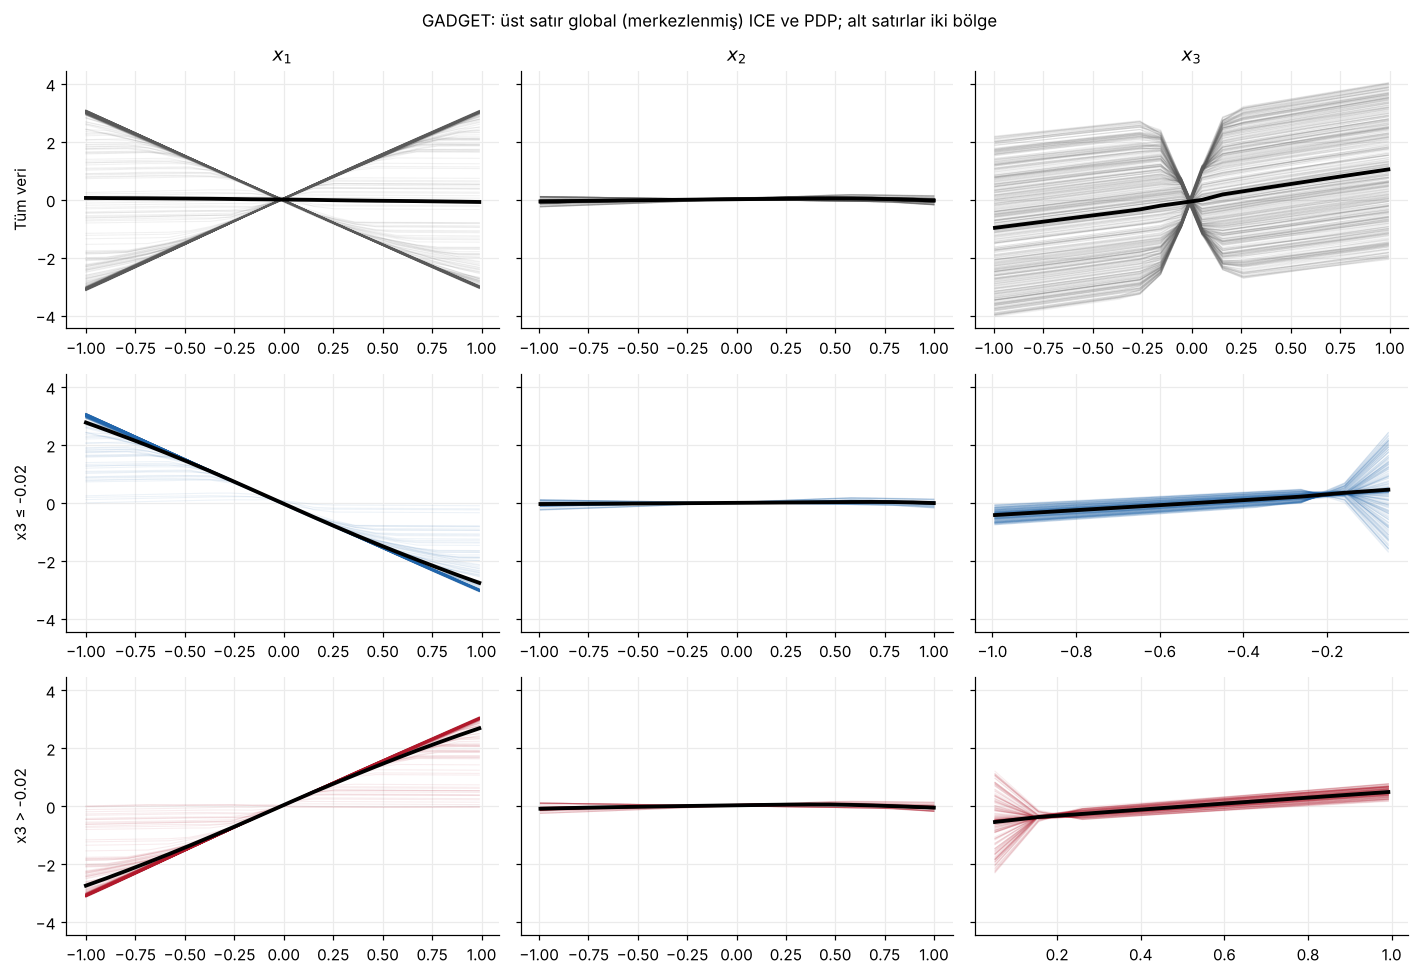

     bölge öznitelik  bölgesel PDP eğimi ızgara aralığı
  Tüm veri        x1               -0.07   -1.00 – 0.99
  Tüm veri        x2                0.04   -0.99 – 1.00
  Tüm veri        x3                1.04   -0.99 – 0.99
x3 ≤ -0.02        x1               -2.86   -1.00 – 0.99
x3 ≤ -0.02        x2                0.03   -0.99 – 1.00
x3 ≤ -0.02        x3                0.92  -0.99 – -0.05
x3 > -0.02        x1                2.80   -1.00 – 0.99
x3 > -0.02        x2                0.04   -0.99 – 1.00
x3 > -0.02        x3                1.07    0.05 – 0.99


In [5]:
fig, eks = plt.subplots(3, 3, figsize=(13, 9), sharey=True)
satirlar = [("Tüm veri", {"idx": np.arange(len(X_sim)), "izgara": {j: np.ones(20, bool) for j in ICE_sim}}, "0.35")]
satirlar += [(" & ".join(d["kural"]), d, r) for d, r in zip(yap_sim, ["#2166ac", "#b2182b"])]
egimler = []
for s, (ad, d, renk) in enumerate(satirlar):
    for c, j in enumerate(["x1", "x2", "x3"]):
        z, pdp, Y = bolgesel_pdp(ICE_sim, d, j)
        ax = eks[s, c]
        ax.plot(z, Y.T, color=renk, alpha=0.08, lw=0.7)
        ax.plot(z, pdp, color="k", lw=2.5)
        if s == 0:
            ax.set_title(f"${j[0]}_{j[1]}$", fontsize=12)
        if c == 0:
            ax.set_ylabel(ad, fontsize=10)
        egimler.append({"bölge": ad, "öznitelik": j, "bölgesel PDP eğimi": np.polyfit(z, pdp, 1)[0],
                        "ızgara aralığı": f"{z.min():.2f} – {z.max():.2f}"})
fig.suptitle("GADGET: üst satır global (merkezlenmiş) ICE ve PDP; alt satırlar iki bölge", fontsize=11)
fig.tight_layout()
goster(fig, "01_simulasyon_gadget.png")
print(pd.DataFrame(egimler).round(2).to_string(index=False))

**Yorum.** GADGET makaledeki gibi $x_3 \approx 0$'da bölüyor. Bölünmeden sonra $x_1$'in heterojenliği neredeyse tamamen
kayboluyor: her bölgede $x_1$'in eğimi tek ve gerçek değere (±3) yakın. $x_3$ hem ilgilenilen hem bölünen öznitelik
olduğu için ızgarası her bölgede kendi yarısıyla sınırlanıyor (solda −1…0, sağda 0…1). $x_2$'nin eğrileri zaten düz.

**Sağlamlık:** 20 farklı tohumla aynı deney.

In [6]:
sonuc = []
for tohum in range(20):
    Xs, ys = xor_veri(500, tohum)
    m = Pipeline([("olcek", StandardScaler()),
                  ("ag", MLPRegressor(hidden_layer_sizes=(20,), alpha=1e-3, max_iter=5000, random_state=tohum))]).fit(Xs, ys)
    ICE_t = {j: ice_hesapla(m.predict, Xs, j, ICE_IZGARA[j]) for j in ["x1", "x2", "x3"]}
    yp, b, _ = gadget(ICE_t, Xs, derinlik=1, esik=0.0, min_dugum=1, n_kantil=100)
    e = [np.polyfit(*bolgesel_pdp(ICE_t, d, "x1")[:2], 1)[0] for d in yp]
    sonuc.append({"bölünen": b.iloc[0]["öznitelik"], "eşik": b.iloc[0]["eşik"], "x1 eğimi (sol)": e[0], "x1 eğimi (sağ)": e[1]})
sonuc = pd.DataFrame(sonuc)
print(f"Bölünen öznitelik x3: {(sonuc['bölünen'] == 'x3').sum()}/20")
print(f"Eşik: ortalama {sonuc['eşik'].mean():.3f}, aralık {sonuc['eşik'].min():.2f} – {sonuc['eşik'].max():.2f}")
print(f"x1 eğimi: solda ortalama {sonuc['x1 eğimi (sol)'].mean():.2f}, sağda ortalama {sonuc['x1 eğimi (sağ)'].mean():.2f}")

Bölünen öznitelik x3: 20/20
Eşik: ortalama -0.003, aralık -0.04 – 0.03
x1 eğimi: solda ortalama -2.79, sağda ortalama 2.79


## 3. Makalenin gerçek veri örneği: saatlik bisiklet verisi (makale Bölüm 1; `bike.R`)

Yazarların kurgusu: ISLR2 `Bikeshare` (8.645 saat, 2011). Öznitelikler: `day, hr, temp, windspeed, workingday, hum,
season, weathersit, atemp, casual`; hedef saatlik kiralama sayısı (`bikers`). Tek "heavy rain/snow" gözlemi çıkarılıyor.
Model: rastgele orman (`ranger`), bütün veriyle eğitiliyor. Saat (`hr`) için 10 noktalı ICE; bölme özniteliği
$Z = \{$`workingday`$\}$, bir bölünme, `esik = 0,1`, `min_dugum = 50`.

**Makalenin Bölüm 1 şekli:** Saat için global PDP ile iş gününe göre bölünmüş iki bölgesel PDP yan yana gösteriliyor.

In [7]:
bis = veri_oku("bisiklet")
bis = bis[bis["weathersit"] != "heavy rain/snow"].reset_index(drop=True)
bis["hr"] = bis["hr"].astype(float)
bis["weathersit"] = bis["weathersit"].map({"clear": 1, "cloudy/misty": 2, "light rain/snow": 3})
BIS_OZ = ["day", "hr", "temp", "windspeed", "workingday", "hum", "season", "weathersit", "atemp", "casual"]
print(bis.shape)
rf_bis = RandomForestRegressor(n_estimators=500, max_features=3, min_samples_leaf=5, random_state=123, n_jobs=-1)
egit_b, test_b = train_test_split(bis, test_size=0.2, random_state=123)
rf_bis.fit(egit_b[BIS_OZ], egit_b["bikers"])
print(f"Rastgele orman, ayrılmış test kümesinde R² = {r2_score(test_b['bikers'], rf_bis.predict(test_b[BIS_OZ])):.3f}"
      "   (makale, 5 katlı çapraz doğrulama: 0,940)")
rf_bis.fit(bis[BIS_OZ], bis["bikers"])                       # yazarlar gibi bütün veriyle

ICE_IZGARA["hr"] = np.linspace(bis["hr"].min(), bis["hr"].max(), 10)
ICE_bis = {"hr": ice_hesapla(lambda D: rf_bis.predict(D[BIS_OZ]), bis[BIS_OZ], "hr", ICE_IZGARA["hr"])}
yap_bis, bol_bis, _ = gadget(ICE_bis, bis[["workingday"]], derinlik=1, esik=0.1, min_dugum=50)
print(bol_bis.round(3).to_string(index=False))

# Genişletme: bölme adayı olarak bütün öznitelikler verilince de iş günü mü seçiliyor?
yap_bis2, bol_bis2, _ = gadget(ICE_bis, bis[[c for c in BIS_OZ if c != "hr"]], derinlik=1, esik=0.1, min_dugum=50)
print("\nBütün öznitelikler aday olunca:")
print(bol_bis2.round(3).to_string(index=False))

(8644, 15)


Rastgele orman, ayrılmış test kümesinde R² = 0.915   (makale, 5 katlı çapraz doğrulama: 0,940)


 derinlik bölünen düğüm  öznitelik  eşik  kazanç    n
        1      tüm veri workingday   0.5   0.274 8644



Bütün öznitelikler aday olunca:
 derinlik bölünen düğüm  öznitelik  eşik  kazanç    n
        1      tüm veri workingday   0.5   0.274 8644


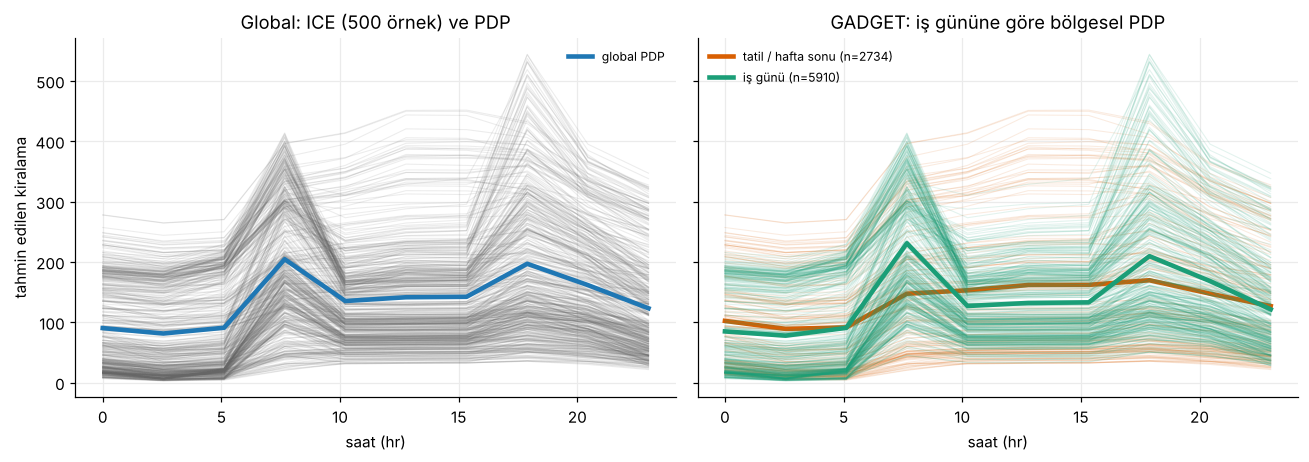

In [8]:
ornek = np.random.default_rng(123).choice(len(bis), 500, replace=False)
z = ICE_IZGARA["hr"]
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
a.plot(z, ICE_bis["hr"][ornek].T, color="0.4", alpha=0.12, lw=0.7)
a.plot(z, ICE_bis["hr"].mean(0), color="#1f77b4", lw=3, label="global PDP")
a.set(xlabel="saat (hr)", ylabel="tahmin edilen kiralama", title="Global: ICE (500 örnek) ve PDP")
a.legend(fontsize=8)
etiket = {0: "tatil / hafta sonu", 1: "iş günü"}
for d, r in zip(yap_bis, ["#d95f02", "#1b9e77"]):
    w = int(bis["workingday"].iloc[d["idx"]].iloc[0])
    sec = np.intersect1d(ornek, d["idx"])
    b.plot(z, ICE_bis["hr"][sec].T, color=r, alpha=0.12, lw=0.7)
    b.plot(z, ICE_bis["hr"][d["idx"]].mean(0), color=r, lw=3, label=f"{etiket[w]} (n={len(d['idx'])})")
b.set(xlabel="saat (hr)", title="GADGET: iş gününe göre bölgesel PDP")
b.legend(fontsize=8)
fig.tight_layout()
goster(fig, "02_bisiklet_gadget.png")

**Yorum.** GADGET makaledeki gibi iş gününe bölüyor (kazanç %27,4). Global PDP'deki sabah ve akşam tepeleri aslında
iş günlerine ait (verinin %68'i); tatil günlerinde ise öğle saatlerinde geniş, tek bir yükselme var ve bu örüntü global
PDP'de görünmüyor. Bütün öznitelikler bölme adayı olduğunda da ağacın ilk seçimi yine iş günü: ayrım veriden
kendiliğinden çıkıyor.

**Makaleden farklarım:** `ranger` yerine scikit-learn rastgele ormanı; 10 noktalı ızgara aynı.

## 4. Kendi verim: Bölüm 13 uygulamamdaki model, gelir ve bina yaşı birlikte

Bölüm 13 uygulamamda aynı veride gradient boosting modeli kurmuş, 400 test bölgesi için **medyan gelir** ICE'lerini
hesaplamış ve eğrilerin **bina yaşına** göre farklılaştığını bulmuştum.

GADGET'in REPID'den farkı birden çok özniteliğe aynı anda bakabilmesi. Ama sonuç iki seçime bağlı: ilgilenilen
öznitelikler $S$ ve bölme adayları $Z$. Dört kurguyu karşılaştırıyorum (okyanusa yakınlık sıralı tamsayı; `derinlik = 2`,
`esik = 0,1`, `min_dugum = 30`):

| Kurgu | $S$ | $Z$ (bölme adayları) |
|---|---|---|
| A · Tek öznitelik (REPID'e eşdeğer) | gelir | gelir dışındakiler |
| B · Birlikte | gelir, bina yaşı | gelir dışındakiler (bina yaşı aday) |
| C · Birlikte | gelir, bina yaşı | hepsi |
| D · Birlikte | gelir, bina yaşı | $S$ dışındakiler |

In [9]:
ev = veri_oku("california")
ev["median_house_value"] = ev["median_house_value"] / 100_000
SAYISAL = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
           "population", "households", "median_income"]
OZ = SAYISAL + ["ocean_proximity"]
e_egitim, e_test = train_test_split(ev, train_size=2 / 3, random_state=42)          # uygulamamla aynı bölme
ev_model = Pipeline([
    ("on", ColumnTransformer([("kat", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"])],
                             remainder="passthrough", sparse_threshold=0)),
    ("gb", HistGradientBoostingRegressor(max_iter=600, learning_rate=0.08, max_leaf_nodes=31, random_state=42)),
]).fit(e_egitim[OZ], e_egitim["median_house_value"])
print(f"Gradient boosting test R² = {r2_score(e_test['median_house_value'], ev_model.predict(e_test[OZ])):.3f}, "
      f"MAE = {mean_absolute_error(e_test['median_house_value'], ev_model.predict(e_test[OZ])) * 100_000:,.0f} $")

YAKINLIK = {"INLAND": 1, "<1H OCEAN": 2, "NEAR BAY": 3, "NEAR OCEAN": 4, "ISLAND": 5}
GELIR, YAS = "median_income", "housing_median_age"
ICE_IZGARA[GELIR] = np.linspace(e_egitim[GELIR].quantile(0.01), e_egitim[GELIR].quantile(0.99), 50)
ICE_IZGARA[YAS] = np.linspace(e_egitim[YAS].min(), e_egitim[YAS].max(), 20)


def kurgular(Xs):
    """Dört kurgu için (ICE sözlüğü, bölme adayları)."""
    I = {j: ice_hesapla(ev_model.predict, Xs, j, ICE_IZGARA[j]) for j in [GELIR, YAS]}
    Xb = Xs.assign(ocean_proximity=Xs["ocean_proximity"].map(YAKINLIK))
    return I, {
        "A · Tek öznitelik": ({GELIR: I[GELIR]}, Xb.drop(columns=[GELIR])),
        "B · Birlikte, yaş aday": (I, Xb.drop(columns=[GELIR])),
        "C · Birlikte, hepsi aday": (I, Xb),
        "D · Birlikte, S aday değil": (I, Xb.drop(columns=[GELIR, YAS])),
    }


Xe = e_test[OZ].sample(400, random_state=1).reset_index(drop=True)                  # uygulamamdaki 400 bölge
ICE_ev, KURGU = kurgular(Xe)
ozet, sonuclar = [], {}
for ad, (I, Z) in KURGU.items():
    yp, b, _ = gadget(I, Z, derinlik=2, esik=0.1, min_dugum=30)
    sonuclar[ad] = (I, yp, b)
    ob = oznitelik_basina(I, yp)
    ozet.append({"kurgu": ad,
                 "ilk bölünme": f"{b.iloc[0]['öznitelik']} ≤ {b.iloc[0]['eşik']:.2f}" if len(b) else "bölünme yok",
                 "ilk kazanç": round(b.iloc[0]["kazanç"], 3) if len(b) else 0.0, "yaprak": len(yp),
                 "gelir heterojenliği azalma (%)": ob.loc[GELIR, "azalma (%)"],
                 "bina yaşı heterojenliği azalma (%)": ob.loc[YAS, "azalma (%)"] if YAS in ob.index else np.nan})
print(pd.DataFrame(ozet).to_string(index=False))
print("\nB kurgusunun bölünmeleri:")
print(sonuclar["B · Birlikte, yaş aday"][2].round(3).to_string(index=False))

Gradient boosting test R² = 0.838, MAE = 31,030 $


                     kurgu                ilk bölünme  ilk kazanç  yaprak  gelir heterojenliği azalma (%)  bina yaşı heterojenliği azalma (%)
         A · Tek öznitelik housing_median_age ≤ 27.50       0.164       4                           29.06                                 NaN
    B · Birlikte, yaş aday housing_median_age ≤ 27.50       0.274       4                           29.06                               84.44
  C · Birlikte, hepsi aday       median_income ≤ 5.02       0.685       3                           90.08                               28.82
D · Birlikte, S aday değil                bölünme yok       0.000       1                            0.00                                0.00

B kurgusunun bölünmeleri:
 derinlik              bölünen düğüm          öznitelik     eşik  kazanç   n
        1                   tüm veri housing_median_age   27.500   0.274 400
        2 housing_median_age ≤ 27.50        total_rooms 1312.606   0.039 191
        2 housing_median_age > 2

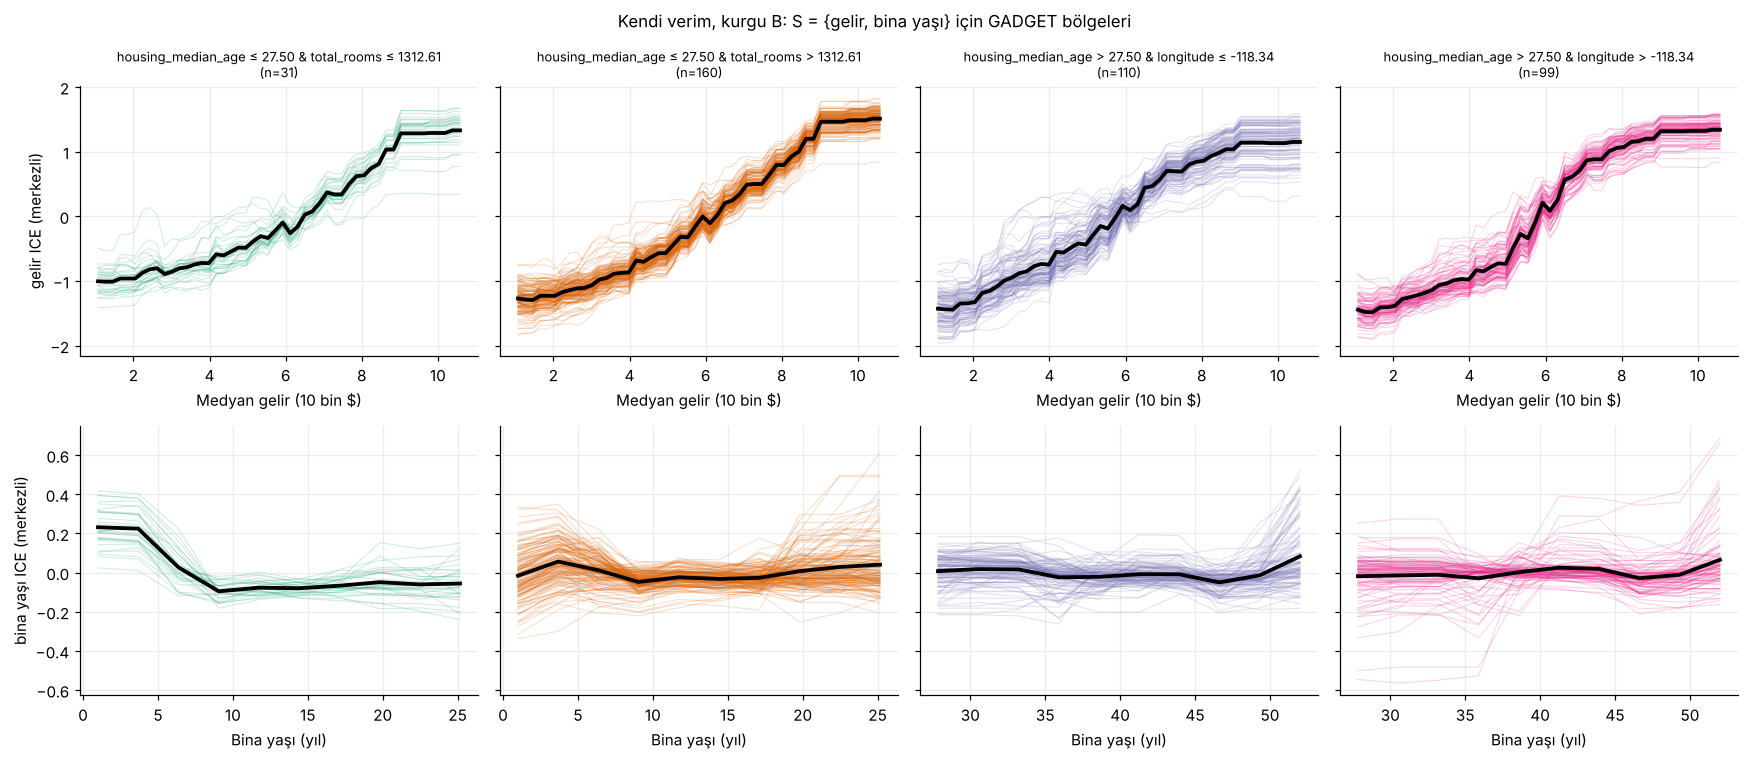

In [10]:
I_B, yap_B, _ = sonuclar["B · Birlikte, yaş aday"]
fig, eks = plt.subplots(2, len(yap_B), figsize=(4 * len(yap_B), 7), sharey="row")
for c, (d, r) in enumerate(zip(yap_B, BOLGE_RENK)):
    for s, j in enumerate([GELIR, YAS]):
        z, pdp, Y = bolgesel_pdp(I_B, d, j)
        eks[s, c].plot(z, Y.T, color=r, alpha=0.2, lw=0.7)
        eks[s, c].plot(z, pdp, color="k", lw=2.5)
        eks[s, c].set_xlabel({GELIR: "Medyan gelir (10 bin $)", YAS: "Bina yaşı (yıl)"}[j])
    eks[0, c].set_title(f"{' & '.join(d['kural'])}\n(n={len(d['idx'])})", fontsize=8.5)
eks[0, 0].set_ylabel("gelir ICE (merkezli)")
eks[1, 0].set_ylabel("bina yaşı ICE (merkezli)")
fig.suptitle("Kendi verim, kurgu B: S = {gelir, bina yaşı} için GADGET bölgeleri", fontsize=11)
fig.tight_layout()
goster(fig, "03_kendi_veri_gadget.png")

**Yorum.**

* **A, REPID'e eşdeğer** tek öznitelikli bölme: ilk bölünme bina yaşı ≤ 27,5, kazanç %16,4. Bu, Bölüm 13 uygulamamda
  gelir c-ICE kümelerinin bina yaşıyla ilişkili çıkmasıyla tutarlı.
* **B (birlikte)** da bina yaşından bölüyor. Öznitelik başına bakınca gelirin heterojenliği yaklaşık %29 azalıyor: bu
  etkileşim. Bina yaşınınki çok daha fazla azalıyor, ama bunun büyük kısmı yaşın hem bölünen hem incelenen öznitelik
  olmasından geliyor: her bölgede yaşın ızgarası kendi yarısına daralıyor.
* **C (hepsi aday)** geliri gelire göre bölüyor. Makale, incelenen özniteliğin aynı zamanda bölme özniteliği olmasına
  izin veriyor; bu yüzden bu bölünme kendi başına hata değil. Ama yüksek kazanç ızgaranın daralmasını da içeriyor (aşağıdaki
  kontrol: gelir için daraltılmış ızgarada ve tam ızgarada). Bu yüzden doğrudan daha güçlü bir etkileşim bulunduğu
  şeklinde yorumlanmamalı.
* **D (S aday değil)** hiç bölmüyor: gelir ve bina yaşının ortak heterojenliğinin %10'unu tek başına açıklayan başka bir
  öznitelik yok.

*Tablodaki "ilk kazanç" ilk bölünmeye; öznitelik sütunları ağacın son yapraklarındaki toplam heterojenlik azalmasına aittir.*

**Ders:** GADGET'in sonucu $S$ ve $Z$ seçimine çok duyarlı. Bölünen öznitelik $S$'nin içindeyse kazancı yorumlarken
ızgara kısıtlamasını ayırmak gerekiyor; öznitelik başına tablo bunu sağlıyor.

In [11]:
# Kontrol: C kurgusunda heterojenlik azalmasının ne kadarı ızgaranın daralmasından geliyor?
# Aynı yapraklar için azalmayı bir de tam ızgara korunarak (eğriler kökteki gibi merkezli) hesaplıyorum.
I_C, yap_C, _ = sonuclar["C · Birlikte, hepsi aday"]
kontrol = []
for j in [GELIR, YAS]:
    Yk = merkezle(I_C[j])
    tam = sum(heterojenlik(Yk[d["idx"]]) for d in yap_C)
    kontrol.append({"öznitelik": j, "daraltılmış ızgara (%)": oznitelik_basina(I_C, yap_C).loc[j, "azalma (%)"],
                    "tam ızgara (%)": round(100 * (1 - tam / heterojenlik(Yk)), 2)})
print(pd.DataFrame(kontrol).to_string(index=False))

         öznitelik  daraltılmış ızgara (%)  tam ızgara (%)
     median_income                   90.08            2.89
housing_median_age                   28.82           28.82


Gelirde azalmanın neredeyse tamamı ızgaranın daralmasından geliyor; bina yaşı eğrilerindeki azalma ise iki hesapta aynı.

**Sağlamlık:** 400 bölge küçük bir örneklem. A ve B kurgularının ilk bölünmesini beş farklı 400'lük örneklem ve 2.000
bölgelik bir örneklemle kontrol ediyorum.

In [12]:
ilk = []
for boyut, tohum in [(400, 1), (400, 2), (400, 3), (400, 4), (400, 5), (2000, 1)]:
    _, K = kurgular(e_test[OZ].sample(boyut, random_state=tohum).reset_index(drop=True))
    satir = {"örneklem": f"{boyut} bölge, tohum {tohum}"}
    for ad in ["A · Tek öznitelik", "B · Birlikte, yaş aday"]:
        _, b, _ = gadget(*K[ad], derinlik=1, esik=0.1, min_dugum=30)
        satir[ad] = f"{b.iloc[0]['öznitelik']} ≤ {b.iloc[0]['eşik']:.1f} ({b.iloc[0]['kazanç']:.3f})" if len(b) else "bölünme yok"
    ilk.append(satir)
print(pd.DataFrame(ilk).to_string(index=False))

           örneklem                 A · Tek öznitelik            B · Birlikte, yaş aday
 400 bölge, tohum 1 housing_median_age ≤ 27.5 (0.164) housing_median_age ≤ 27.5 (0.274)
 400 bölge, tohum 2 housing_median_age ≤ 27.5 (0.159) housing_median_age ≤ 27.5 (0.271)
 400 bölge, tohum 3 housing_median_age ≤ 26.5 (0.161) housing_median_age ≤ 26.5 (0.265)
 400 bölge, tohum 4 housing_median_age ≤ 27.5 (0.170) housing_median_age ≤ 27.5 (0.277)
 400 bölge, tohum 5 housing_median_age ≤ 27.5 (0.166) housing_median_age ≤ 27.5 (0.288)
2000 bölge, tohum 1 housing_median_age ≤ 27.5 (0.164) housing_median_age ≤ 27.5 (0.279)


## 5. Sınırlamalar (savunma için)

1. **Açgözlü ağaç.** Her adımda en iyi tek bölünme seçilir; bölünmeler eksenlere paraleldir.
2. **Izgara kısıtlama.** Bölünen öznitelik $S$'deyse ızgarası daralır ve kazanç bu daralmayı da içerir; azalmanın bir
   kısmı daha kısa bir aralığa bakmaktan gelir. Kazancı öznitelik başına ve tam ızgarayla karşılaştırarak yorumlamak gerekir.
3. **Korelasyonlu öznitelikler.** İki öznitelik çok bağlıysa ağaç birini seçer; gerçek etkileşim ortağını ayıramaz.
   ICE eğrileri de bu durumda veri dışı noktalar içerebilir (Bölüm 12 makale çalışmamın konusu).
4. **Ayar seçimi.** Bölge sayısı `esik`, `derinlik`, `min_dugum` ve $S$/$Z$ seçimine bağlı.
5. **Yeniden üretilmeyenler.** Makalenin ALE ve SHAP sürümleri, etkileşim için permütasyon testi (PINT), korelasyon ve
   yüksek dereceli etkileşim simülasyonları (Bölüm 6–7) ve COMPAS/spam örnekleri.
6. **Model açıklaması, gerçek dünya değil.** Bulunan etkileşimler modelin etkileşimleridir; nedensel yorumlanamaz.